In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

print("Размер датасета:", X.shape)
print("Количество признаков:", X.shape[1])
print("Классы:", cancer.target_names)

Размер датасета: (569, 30)
Количество признаков: 30
Классы: ['malignant' 'benign']


In [3]:
df = pd.DataFrame(X, columns=cancer.feature_names)
df["target"] = y

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


target
benign       357
malignant    212
Name: count, dtype: int64


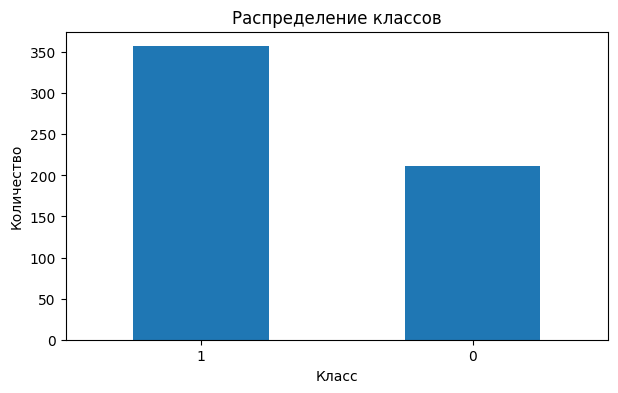

In [4]:
print(df["target"].value_counts().rename(index={
    0: "malignant",
    1: "benign"
}))

df["target"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.xticks(rotation=0)
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)


In [6]:
rf_original = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_original.fit(X_train, y_train)

y_pred_original = rf_original.predict(X_test)
accuracy_original = accuracy_score(y_test, y_pred_original)

print("Accuracy на исходных признаках:", round(accuracy_original, 4))

Accuracy на исходных признаках: 0.9561


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Количество признаков до PCA:", X_train.shape[1])
print("Количество признаков после PCA:", X_train_pca.shape[1])
print("Сохранённая дисперсия:", round(sum(pca.explained_variance_ratio_), 4))

Количество признаков до PCA: 30
Количество признаков после PCA: 10
Сохранённая дисперсия: 0.9527


In [8]:
rf_pca = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_pca.fit(X_train_pca, y_train)

y_pred_pca = rf_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("Accuracy после PCA:", round(accuracy_pca, 4))

Accuracy после PCA: 0.9211


In [9]:
print("Сравнение моделей:")
print("До PCA:", round(accuracy_original, 4))
print("После PCA:", round(accuracy_pca, 4))

difference = accuracy_original - accuracy_pca

print("Изменение качества:", round(difference, 4))
print("Изменение в процентных пунктах:", round(difference * 100, 2))

Сравнение моделей:
До PCA: 0.9561
После PCA: 0.9211
Изменение качества: 0.0351
Изменение в процентных пунктах: 3.51


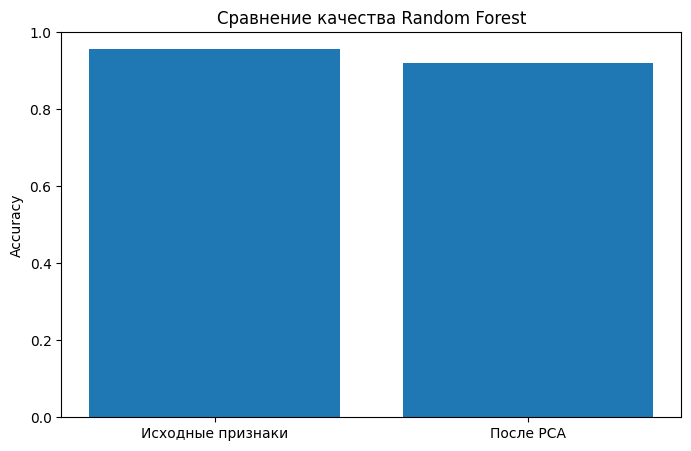

In [10]:
results = pd.DataFrame({
    "Метод": ["Исходные признаки", "После PCA"],
    "Accuracy": [accuracy_original, accuracy_pca]
})

plt.figure(figsize=(8, 5))
plt.bar(results["Метод"], results["Accuracy"])
plt.title("Сравнение качества Random Forest")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [11]:
%pip install umap-learn --quiet

In [12]:
import umap

X_scaled = StandardScaler().fit_transform(X)

umap_model = umap.UMAP(
    n_components=2,
    random_state=42
)

X_umap = umap_model.fit_transform(X_scaled)

print("Размерность после UMAP:", X_umap.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Размерность после UMAP: (569, 2)


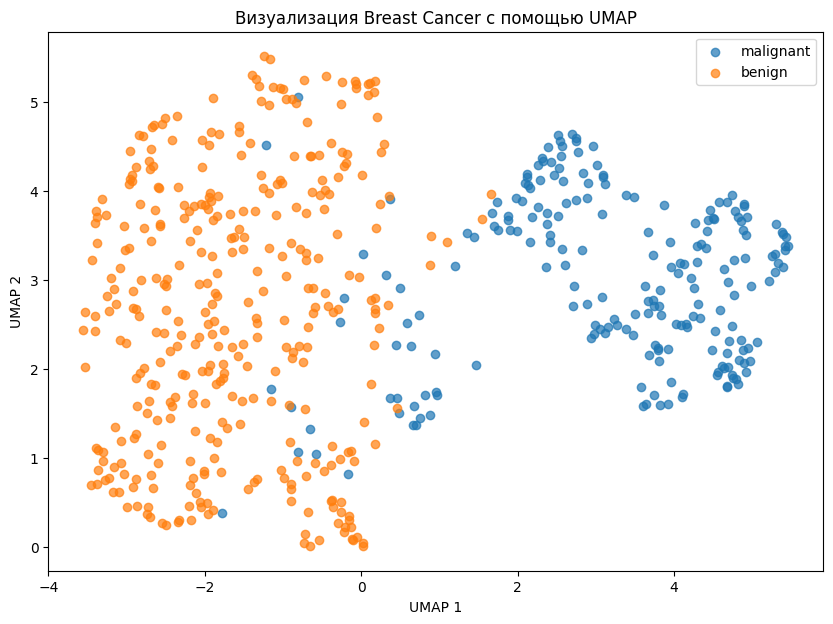

In [13]:
plt.figure(figsize=(10, 7))

for class_id, class_name in enumerate(cancer.target_names):
    mask = y == class_id

    plt.scatter(
        X_umap[mask, 0],
        X_umap[mask, 1],
        label=class_name,
        alpha=0.7
    )

plt.title("Визуализация Breast Cancer с помощью UMAP")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.show()

До применения PCA модель RandomForestClassifier показала Accuracy = 0.9561 (95.61%).

После применения PCA количество признаков сократилось с 30 до 10, при этом сохранилось 95.27% исходной дисперсии. Точность модели составила 0.9211 (92.11%).

Таким образом, качество классификации снизилось на 3.51 процентного пункта.

Итог: PCA позволил сократить количество признаков в 3 раза, сохранив большую часть информации. Однако это привело к небольшому снижению точности модели. Поэтому в данном случае исходные признаки обеспечивают более высокое качество классификации.